# Activity 6.5 Preparing for time series analysis in Python

## Scenario
The Baltimore Police Department (BPD), situated in Baltimore, USA, created a data set containing crime records from 1 January 2011 to 18 June 2016. Although the data set is considered preliminary and subject to change, it contains 264,496 rows and 11 columns (BPD, 2024).

For this activity, the data set was adapted to indicate the number of daily crime incidents from 1 January 2011 to 31 December 2015. Therefore, the data set contains 2,143 rows and 2 columns. You are tasked to analyse the provided data set to determine visible crime trends. You must also provide a clear and precise rationale for your analysis and findings.


## Objective
In this portfolio activity, you will analyse a time series data set to gain insights into crime trends.

You will complete the activity in your Notebook, where you will:
- preprocess the data
- visualise the data
- calculate and compare ACF and PACF
- transform and decompose the data
- perform statistical analysis
- present your insights based on statistical tests and visualisations.


## Assessment criteria
By completing this activity, you will be able to provide evidence that you can:
- Synthesise autocorrelation and stationarity concepts and define their importance in time series analysis.
- Recognise white noise, identify random walk behaviour processes in time series, and apply statistical tests for model diagnostics.
- Accurately perform time series decomposition, including seasonality, trend, and residual components, and apply transformations to make time series stationary.
- Critically evaluate the effectiveness of time series analysis to address real-world problems.



## Activity guidance
1. Import the relevant libraries for data analysis and visualisation.
2. Explore and preprocess the data set.
3. Preprocess the data, handling missing values and encoding categorical variables as needed.
4. Handle missing values and compare results.
5. Create a new DataFrame with weekly-grouped daily-average and visualise the data.
6.  Calculate the ACF and PACF with 1% insignificance region around zero of monthly data. Thereafter, interpret the output.
7. Determine if data should be transformed.
8. Decompose the data and determine the STL residuals. Store the residuals as `stl_object.resid`.
9. Apply Ljung-Box and ADF tests on the data.
10. Provide a clear and precise rationale for your data analysis and interpretation.

In [ ]:
# Import the relevant libraries for data analysis and visualisation.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rc
from statsmodels.tsa.seasonal import STL
from scipy.stats import boxcox
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

In [ ]:
# Import data set from GitHub repository:
url = '<path-to-dataset>/crime_incidents.csv'

In [ ]:
df = pd.read_csv(url)
df.head()

,date,incidents
0,01-01-11,185.0
1,01-01-12,176.0
2,01-01-13,157.0
3,01-01-14,139.0
4,01-01-15,157.0


In [ ]:
# Explore and preprocess the data set.
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2143 entries, 0 to 2142
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       2143 non-null   object 
 1   incidents  2069 non-null   float64
dtypes: float64(1), object(1)
memory usage: 33.6+ KB


,0
date,0
incidents,74


In [ ]:
df.tail()

,date,incidents
2138,12/31/2011,112.0
2139,12/31/2012,125.0
2140,12/31/2013,128.0
2141,12/31/2014,108.0
2142,12/31/2015,97.0


In [ ]:
df.shape

(2143, 2)

In [ ]:
# Fixing date as it is an object
# 1. Convert the mixed-format strings to real datetimes (US month-first)
df["date"] = pd.to_datetime(df["date"], format="mixed", dayfirst=False)

# 2. Set date as index, sort ascending, set daily frequency (needed for grouping/STL later)
df.set_index("date", inplace=True)
df.sort_index(inplace=True)
df = df.asfreq("d")

df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2143 entries, 2011-01-01 to 2016-11-12
Freq: D
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   incidents  2069 non-null   float64
dtypes: float64(1)
memory usage: 33.5 KB


In [ ]:
# describe stats
df.describe()

,incidents
count,2069.000000
mean,133.571290
std,22.940221
min,31.000000
25%,120.000000
50%,134.000000
75%,148.000000
max,419.000000


In [ ]:
# Step 3/4: Handle missing values.
# No categorical variables present (date=datetime, incidents=numeric), so no encoding needed.
# Impute the 74 gaps two ways to compare results.
df['incidents_imputed_linear'] = df['incidents'].interpolate(method='linear')
df['incidents_imputed_spline'] = df['incidents'].interpolate(method='spline', order=3)

# Confirm both methods filled all gaps.
print('Missing original:', df.isna().sum()['incidents'])
print('Missing linear:', df.isna().sum()['incidents_imputed_linear'])
print('Missing spline:', df.isna().sum()['incidents_imputed_spline'])

Missing original: 74
Missing linear: 0
Missing spline: 0


In [ ]:
# Step 5: Create weekly-grouped daily-average DataFrame.
df_weekly = df.groupby(pd.Grouper(freq='W')).mean().round(2)
df_weekly.head()

,incidents,incidents_imputed_linear,incidents_imputed_spline
date,,,
2011-01-02,143.50,143.50,143.50
2011-01-09,115.86,115.86,115.86
2011-01-16,110.17,110.93,111.54
2011-01-23,116.43,116.43,116.43
2011-01-30,99.00,100.71,102.68


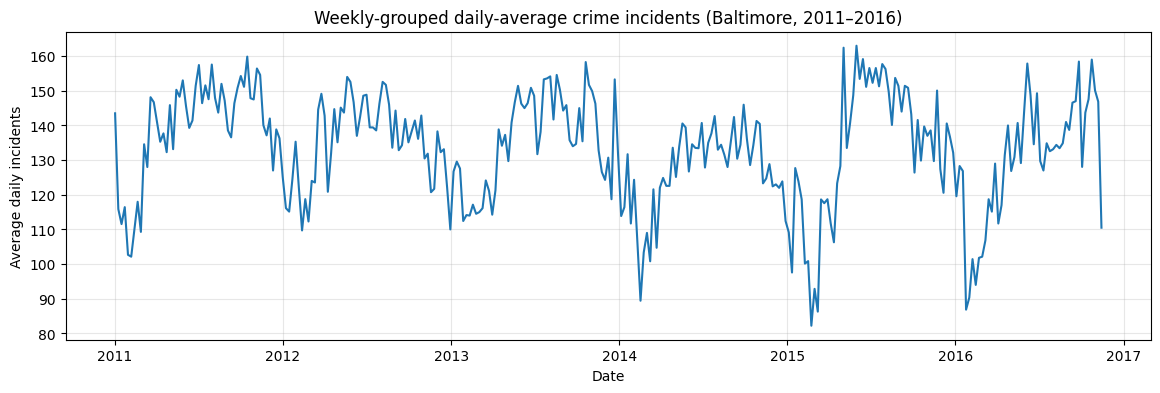

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(df_weekly.index, df_weekly['incidents_imputed_spline'])
plt.title('Weekly-grouped daily-average crime incidents (Baltimore, 2011–2016)')
plt.xlabel('Date')
plt.ylabel('Average daily incidents')
plt.grid(True, alpha=0.3)
plt.show()

There are some sasonality on the data indicating some peaks during summer times and reducing in the winter.

In [ ]:
# Step 6: Group data by month (mean daily incidents per month) for ACF/PACF.
df_monthly = df.groupby(pd.Grouper(freq='ME')).mean().round(2)
df_monthly.head()

,incidents,incidents_imputed_linear,incidents_imputed_spline
date,,,
2011-01-31,112.48,112.53,113.11
2011-02-28,110.93,111.36,111.46
2011-03-31,138.57,139.05,139.21
2011-04-30,138.30,138.30,138.30
2011-05-31,146.00,145.73,146.07


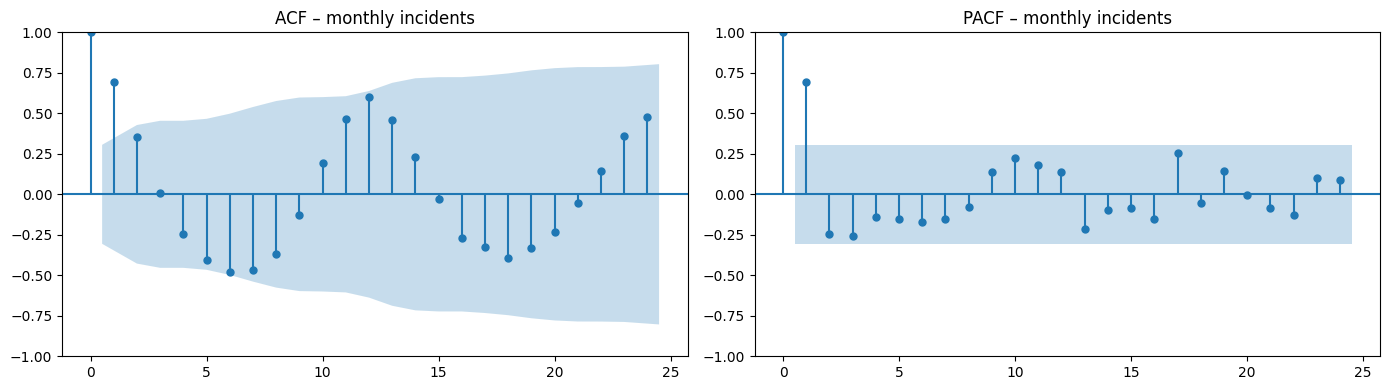

In [ ]:
# Step 6: ACF and PACF with 1% insignificance region (alpha=0.01) on monthly data.
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(df_monthly['incidents_imputed_spline'], lags=24, alpha=0.01, ax=ax[0])
ax[0].set_title('ACF – monthly incidents')
plot_pacf(df_monthly['incidents_imputed_spline'], lags=24, alpha=0.01, method='ywm', ax=ax[1])
ax[1].set_title('PACF – monthly incidents')
plt.tight_layout()
plt.show()

- The slow, wave-like ACF decay (not dropping to zero quickly) indicates the series is not obviously stationary on its own — there's persistent autocorrelation and seasonality.
- The lag-12 ACF bump = annual seasonality to be removed by decomposition.

The chart confirms there is no white noise.

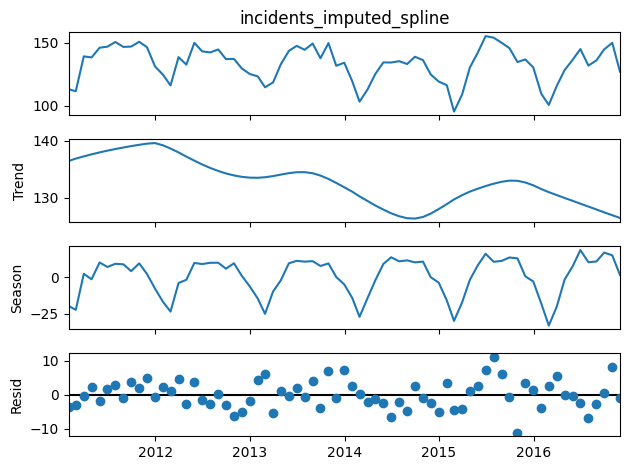

In [ ]:
# Step 8: STL decomposition (trend + seasonal + residual) on monthly data.
# period=12 (annual cycle); additive, no transform per Step 7.
stl_object = STL(df_monthly['incidents_imputed_spline'], period=12, seasonal=9).fit()
stl_object.plot()
plt.show()

Trend is weak, seasonality is strong and regular. Residuals scatter around zero with no clear pattern (roughly −10 to +10). If trend + season captured the real structure well, the residuals should behave like white noise — the Ljung-Box (autocorrelation) and ADF (stationarity) tests will verify this.

In [ ]:
# Step 9: Diagnostics on the STL residuals.
residuals = stl_object.resid

# Ljung-Box test — checks for leftover autocorrelation (H0: residuals are white noise / independent).
ljungbox_results = acorr_ljungbox(residuals, lags=12, return_df=True)
print("Ljung-Box Test:\n", ljungbox_results)

# ADF test — checks for stationarity (H0: series has a unit root / non-stationary).
adf_result = adfuller(residuals)
print(f"\nADF Statistic: {adf_result[0]}")
print(f"p-value: {adf_result[1]}")

Ljung-Box Test:
       lb_stat  lb_pvalue
1    2.020114   0.155227
2    2.487735   0.288267
3    3.645512   0.302374
4    3.758285   0.439706
5    6.807595   0.235348
6    6.811740   0.338609
7    6.916041   0.437674
8    6.971699   0.539689
9    6.982491   0.638942
10   7.000041   0.725441
11   7.084653   0.792187
12  26.544673   0.008981

ADF Statistic: -4.435643265320831
p-value: 0.0002565629508698194


The raw series in the residuals is non-stationary (strong seasonality, visible in the ACF's slow decay and lag-12 structure). After STL decomposition removes trend and seasonality, the residuals are stationary (ADF p ≈ 0.0003) — though not fully white noise, as a small seasonal signal remains at lag 12 (Ljung-Box p ≈ 0.009).

In [ ]:
# ADF on the RAW monthly series (to test the original, not just the residuals)
adf_raw = adfuller(df_monthly['incidents_imputed_spline'])
print(f"ADF Statistic (raw): {adf_raw[0]}")
print(f"p-value (raw): {adf_raw[1]}")

ADF Statistic (raw): -1.762416036663482
p-value (raw): 0.3992741759601174


Raw series → non-stationary (ADF p = 0.399)
STL residuals → stationary (ADF p = 0.00026)
STL residuals → but not fully white noise, because Ljung-Box finds leftover seasonality at lag 12 (p = 0.009)

In [ ]:
df_monthly_5yr = df_monthly.loc['2011':'2015']
stl_5yr = STL(df_monthly_5yr['incidents_imputed_spline'], period=12, seasonal=9).fit()
lb_5yr = acorr_ljungbox(stl_5yr.resid, lags=12, return_df=True)
print(lb_5yr)

      lb_stat  lb_pvalue
1    1.312874   0.251875
2    6.169235   0.045748
3    7.699753   0.052642
4    7.727295   0.102094
5    8.916934   0.112424
6    8.921239   0.178056
7   11.591802   0.114807
8   11.680781   0.166025
9   11.737779   0.228499
10  12.257873   0.268169
11  12.260783   0.344364
12  23.220916   0.025908


# Reflect

Baltimore crime incidents follow a strong, stable annual cycle, rising in warmer months and falling in winter - with no major long-term trend across 2011–2016, making the raw series non-stationary in a predictable way (ADF p = 0.399).

Before analysis, approximately 3.45% of the series (74 of 2,143 daily records) contained missing values, which were imputed using spline interpolation rather than removed, preserving the continuous daily structure that time-series methods require; a comparison against linear interpolation showed negligible difference, supporting the robustness of this choice.

Time-series decomposition then separated the seasonal pattern from the underlying level, leaving stationary residuals (ADF p = 0.0003) and confirming the annual cycle as the dominant driver of the series. However, diagnostic testing revealed a small residual seasonal signal at lag 12 (Ljung-Box p = 0.009), indicating the decomposition did not fully capture the yearly pattern.

To probe whether the partial final year (2016 ends in November) contributed to this, the decomposition was re-run on the five complete years (2011–2015): the lag-12 signal weakened (p rose from 0.009 to 0.026) but remained significant, suggesting the incomplete year contributed to, but did not solely cause, the residual seasonality, with STL's smoothing and the reduced sample size also plausible factors.

Overall, decomposition is an effective first approach for understanding Baltimore's crime seasonality and supporting seasonal resource planning, though the persistent lag-12 signal indicates a seasonal forecasting model (e.g. SARIMA) would likely improve accuracy for operational use.

### Reference
BPD, 2024. Baltimore Crime Data. [online]. Available at: <https://data.world/baltimore/baltimore-crime-data>. [Accessed 5 March 2024].  